In [1]:
def transparency_mom(filename,bins_given):
    file2=uproot.open("/data/neutrinos/scratch/pingal/ehouarn_ccqe/NIWG_ehouarn2.root")
    file3=uproot.open(filename)
    mode=file2['NIWGTree']['NIWGEvent/neutmode'].array() ## interaction mode
    targetA=file2['NIWGTree']['NIWGEvent/targetA'].array()## C in our case
    Nprimary=file2['NIWGTree']['NIWGEvent/NPrimary'].array() ## number of particles in primary interaction
    Nupdg=file2['NIWGTree']['NIWGEvent/NuPDG'].array() ##  numu beam
    truenuE=file2['NIWGTree']['NIWGEvent/TrueEnu'].array() ## fixed energy beam
    Q2=file2['NIWGTree']['NIWGEvent/Q2'].array() ## Q2
    q3=file2['NIWGTree']['NIWGEvent/q3'].array() ## q3
    q0=file2['NIWGTree']['NIWGEvent/q0'].array() ## q0
    W=file2['NIWGTree']['NIWGEvent/W'].array() ## W
    Emiss=file2['NIWGTree']['NIWGEvent/Emiss'].array() ## missing energy E
    Pmiss=file2['NIWGTree']['NIWGEvent/Pmiss'].array() ## missing momentum p
    weight=file2['NIWGTree']['NIWGEvent/weight'].array() ## weight
    px=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fX']
    py=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fY']
    pz=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fP']['fZ']
    E=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.p'].array()[:]['fE']
    pdg=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.pdg'].array()
    chase=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.chase'].array() ## whther the particle is alive or not
    parent=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.parent'].array() ## parent
    isatPV=file2['NIWGTree'][ 'NIWGEvent/part_stack/part_stack.isAtPrimaryVertex'].array() ## parent
    angle=file2['NIWGTree']['NIWGEvent/theta_partToNu'].array()
    nuindex=file2['NIWGTree']['NIWGEvent/nu_index'].array()
    nucindex=file2['NIWGTree']['NIWGEvent/isnuc_index'].array()
    flesp_index=file2['NIWGTree']['NIWGEvent/fslep_index'].array() ## Some useful particle stack indicies to pre-calculate
    
    incident_counter_w_med=file3['Events;1']['incident'].array()
    px_gibuu_w_med=file3['Events;1']['momX'].array()
    py_gibuu_w_med=file3['Events;1']['momY'].array()
    pz_gibuu_w_med=file3['Events;1']['momZ'].array()
    E_gibuu_w_med=file3['Events;1']['momE'].array()
    ID_gibuu_w_med=file3['Events;1']['ID'].array()
    charge_gibuu_w_med=file3['Events;1']['Charge'].array()
    history_gibuu_w_med=file3['Events;1']['history'].array()
    prodid_gibuu_w_med=file3['Events;1']['prod_id'].array()
    idx=np.arange(0,len(mode),1)
    mask_chase=ak.sum(chase, axis=1)>0
    idx=idx[mask_chase]
    print(idx,len(idx))  
    idx1, idx3, idx2 = np.intersect1d(idx, incident_counter_w_med, return_indices=True)
    # idx=incident_counter_gibuu_wo_med1[idx]
    idx2=incident_counter_w_med[idx2]
    
    # _, _, idx = np.intersect1d(idx, incident_counter_wo_med, return_indices=True)
    _, _, idx2 = np.intersect1d(idx2, incident_counter_w_med, return_indices=True)
    pdgf=ak.flatten(pdg[idx1])
    chasef=ak.flatten(chase[idx1])
    Ef=ak.flatten(E[idx1])
    Pxf=ak.flatten(px[idx1])
    Pyf=ak.flatten(py[idx1])
    Pzf=ak.flatten(pz[idx1])
    Ptf=np.sqrt(Pxf**2+Pyf**2)
    Costhetaf=Pzf/np.sqrt(Pxf**2+Pyf**2+Pzf**2)
    modef=ak.flatten(mode[idx1]*ak.ones_like(pdg[idx1]))
    enf=ak.flatten(truenuE[idx1]*ak.ones_like(pdg[idx1]))
    # ################################
    pdgf_gibuu_w_med=ak.flatten(ID_gibuu_w_med[idx2][:,2:])
    chargef_gibuu_w_med=ak.flatten(charge_gibuu_w_med[idx2][:,2:])
    historyf_gibuu_w_med=ak.flatten(history_gibuu_w_med[idx2][:,2:])
    pxf_gibuu_w_med=ak.flatten(px_gibuu_w_med[idx2][:,2:])
    pyf_gibuu_w_med=ak.flatten(py_gibuu_w_med[idx2][:,2:])
    pzf_gibuu_w_med=ak.flatten(pz_gibuu_w_med[idx2][:,2:])
    ptf_gibuu_w_med=np.sqrt(pxf_gibuu_w_med**2+pyf_gibuu_w_med**2)
    modef_gibuu=ak.flatten(mode[idx1]*ak.ones_like(px_gibuu_w_med[idx2][:,2:]))
    enf_gibuu=ak.flatten(truenuE[idx1]*ak.ones_like(px_gibuu_w_med[idx2][:,2:]))
    Ef_gibuu_w_med=ak.flatten(E_gibuu_w_med[idx2][:,2:])
    costheta_w_med=pzf_gibuu_w_med/np.sqrt(pxf_gibuu_w_med*pxf_gibuu_w_med+pyf_gibuu_w_med*pyf_gibuu_w_med+pzf_gibuu_w_med*pzf_gibuu_w_med)
    costheta_w_med[costheta_w_med<=np.cos(np.pi)]
    

    M_PROTON = 0.938
    bins_array = bins_given            # range= is ignored when bins is an array; dropped

    def deviation(ax, ay, az, bx, by, bz):
        c = (ax*bx + ay*by + az*bz) / (np.sqrt(ax**2+ay**2+az**2) * np.sqrt(bx**2+by**2+bz**2))
        return np.arccos(np.clip(c, -1.0, 1.0))

    pdg_arr   = pdg[idx1]
    chase_arr = chase[idx1]
    mode_arr  = mode[idx1]
    px_arr, py_arr, pz_arr = px[idx1], py[idx1], pz[idx1]
    is_ccqe = ak.to_numpy(mode_arr == 1)

    px0 = ak.to_numpy(px_arr[:, 3])
    py0 = ak.to_numpy(py_arr[:, 3])
    pz0 = ak.to_numpy(pz_arr[:, 3])
    p0  = np.sqrt(px0**2 + py0**2 + pz0**2)
    hist2, bins1 = np.histogram(p0[is_ccqe], bins=bins_array)

    KE = np.sqrt(px_arr**2 + py_arr**2 + pz_arr**2 + M_PROTON**2) - M_PROTON
    is_p   = (pdg_arr == 2212) & (chase_arr == 1) & (KE > 0.0)
    is_had = (pdg_arr > 99) & (chase_arr == 1)
    one_p  = ak.to_numpy((ak.sum(is_p, axis=1) == 1) & (ak.sum(is_had, axis=1) == 1))

    pxf = ak.to_numpy(ak.fill_none(ak.firsts(px_arr[is_p]), 0.0))
    pyf = ak.to_numpy(ak.fill_none(ak.firsts(py_arr[is_p]), 0.0))
    pzf = ak.to_numpy(ak.fill_none(ak.firsts(pz_arr[is_p]), 0.0))

    sel_neut = is_ccqe & one_p
    ang_ok   = np.zeros(len(p0), dtype=bool)
    ang_ok[sel_neut] = deviation(px0[sel_neut], py0[sel_neut], pz0[sel_neut],pxf[sel_neut], pyf[sel_neut], pzf[sel_neut]) <= np.radians(5)
    hist1, _ = np.histogram(p0[sel_neut & ang_ok], bins=bins_array)

    ID_arr3      = ID_gibuu_w_med[idx2][:, 2:]
    charge_arr3  = charge_gibuu_w_med[idx2][:, 2:]
    prod_id_arr3 = prodid_gibuu_w_med[idx2][:, 2:]
    pxg = px_gibuu_w_med[idx2][:, 2:]
    pyg = py_gibuu_w_med[idx2][:, 2:]
    pzg = pz_gibuu_w_med[idx2][:, 2:]

    KE3 = np.sqrt(pxg**2 + pyg**2 + pzg**2 + M_PROTON**2) - M_PROTON
    is_p3   = (prod_id_arr3 == 1) & (ID_arr3 == 1) & (charge_arr3 == 1) & (KE3 > 0.0)
    is_had3 = (abs(ID_arr3) > 0) & (abs(ID_arr3) < 900)
    one_p3  = ak.to_numpy((ak.sum(is_p3, axis=1) == 1) & (ak.sum(is_had3, axis=1) == 1))

    pxg_f = ak.to_numpy(ak.fill_none(ak.firsts(pxg[is_p3]), 0.0))
    pyg_f = ak.to_numpy(ak.fill_none(ak.firsts(pyg[is_p3]), 0.0))
    pzg_f = ak.to_numpy(ak.fill_none(ak.firsts(pzg[is_p3]), 0.0))

    sel_gibuu = is_ccqe & one_p3
    ang_ok3   = np.zeros(len(p0), dtype=bool)
    ang_ok3[sel_gibuu] = deviation(px0[sel_gibuu], py0[sel_gibuu], pz0[sel_gibuu],
                                   pxg_f[sel_gibuu], pyg_f[sel_gibuu], pzg_f[sel_gibuu]) <= np.radians(5)
    hist11, _ = np.histogram(p0[sel_gibuu & ang_ok3], bins=bins_array)

    assert np.all(hist1  <= hist2), "NEUT numerator not a subset of denominator"
    assert np.all(hist11 <= hist2), "GiBUU numerator not a subset of denominator"

    return hist1, hist2, hist11


In [6]:
import uproot
import numpy as np
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
bins=np.arange(0,5,0.25)
hist1c0p,hist2c0p,hist11c0p=transparency_mom("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test/workdir/test_eos0.root",bins)
hist1c1p,hist2c1p,hist11c1p=transparency_mom("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test/workdir/test_eos1.root",bins)
hist1c3p,hist2c2p,hist11c2p=transparency_mom("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test/workdir/test_eos2.root",bins)
hist1c3p,hist2c3p,hist11c3p=transparency_mom("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test/workdir/test_eos3.root",bins)
hist1c5p,hist2c5p,hist11c5p=transparency_mom("/data/neutrinos/scratch/pingal/GiBUU_kek/release/testRun/jg_test/workdir/test_eos5.root",bins)

[     0      1      2 ... 799997 799998 799999] 800000
[     0      1      2 ... 799997 799998 799999] 800000
[     0      1      2 ... 799997 799998 799999] 800000
[     0      1      2 ... 799997 799998 799999] 800000
[     0      1      2 ... 799997 799998 799999] 800000


Text(0.5, 0, '$p(GeV/c)$')

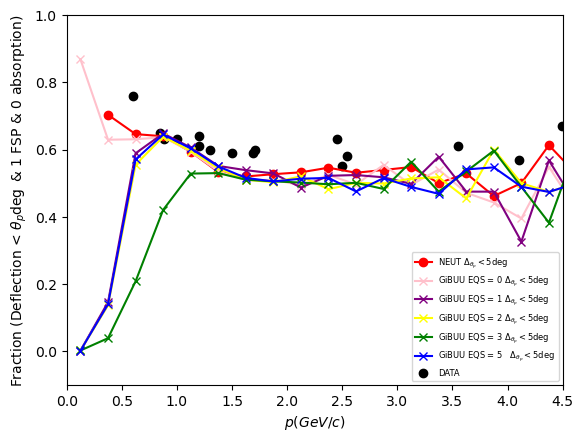

In [7]:
binc=(bins[1:]+bins[:-1])/2
X=np.array([ (0.60,0.76),
    (0.85, 0.65),
    (0.88,0.63),
    (1.00, 0.63),
    (1.20,0.64),
    (1.20,0.61),
    (1.30,0.60),
    (1.50,0.59),
    (1.69,0.59),
    (1.71,0.60),
    (2.45,0.63),
    (2.50,0.55),
    (2.54,0.58),
    (3.55,0.61),
    (4.10,0.57),
    (4.49,0.67),
    (5.15,0.58)])
plt.plot(binc[1:],hist1c0p[1:]/hist2c0p[1:],color="red",marker="o", label=r"NEUT $\Delta_{\theta_p}<5\deg$")
plt.ylim(-0.1,1.0)
plt.plot(binc,hist11c0p/hist2c0p,color="pink",marker="x", label=r"GiBUU EQS = 0 $\Delta_{\theta_p}<5\deg$")
plt.plot(binc,hist11c1p/hist2c1p,color="purple",marker="x", label=r"GiBUU EQS = 1 $\Delta_{\theta_p}<5\deg$")
plt.plot(binc,hist11c2p/hist2c2p,color="yellow",marker="x", label=r"GiBUU EQS = 2 $\Delta_{\theta_p}<5\deg$")
plt.plot(binc,hist11c3p/hist2c3p,color="green",marker="x", label=r"GiBUU EQS = 3 $\Delta_{\theta_p}<5\deg$")
plt.plot(binc,hist11c5p/hist2c5p, color="blue",marker="x", label=r"GiBUU EQS = 5   $\Delta_{\theta_p}<5\deg$")
plt.scatter(X[:,0],X[:,1],color="black",marker="o",label="DATA")
plt.legend(fontsize=6)
plt.xlim(0,4.5)
plt.ylabel(r"Fraction (Deflection < $\theta_p \deg$ & 1 FSP & 0 absorption)")
plt.xlabel(r"$p(GeV/c)$")